# DomainNet: where Ramen and NoAdapt are confused

Runs **Ramen** and the **NoAdapt** baseline (zero-shot CLIP ViT-B/32) on the same DomainNet test stream, keeping the full softmax for every sample (`capture_probs=True` → `results/*_probs.npy`). Then looks at the probability distribution over classes for the classes the models confuse most. Same analysis as `cifar100c_confusion_probs.ipynb`.
DomainNet has no superclasses, so section 2 asks a different question: does the wrong probability mass go to the classes zero-shot CLIP *already* confused each class with, or does adaptation move it somewhere new?

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import numpy as np
import pandas as pd
from ramen_analysis import DomainNetExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = DomainNetExperiment(
    model='clip_vitbase32',
    tta_mode='mixed',      # 'mixed': one shuffled stream over all domains | 'single': each domain separately, reset between
    batch_size=100,
    n_per_domain=None,     # None = whole dataset (~596k images); e.g. 1000 for a quick run (random subset per domain)
    seed=0,
    num_workers=16,        # JPEG decoding is the bottleneck, unlike the in-memory CIFAR arrays
).load()

DomainNet: 6 domains x 596006 images in total, 345 classes, model=clip_vitbase32, mode=mixed


In [3]:
acc = exp.evaluate(capture_probs=True, capture_features=True)   # pass use_cache=False to force a re-run
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
clipart,68.25,69.33,1.08
infograph,43.90,44.98,1.08
painting,64.58,65.70,1.12
quickdraw,13.33,17.54,4.21
real,82.12,82.27,0.15
sketch,60.05,60.96,0.91
average,55.37,56.80,1.43


## 1. Most confused pairs
`true → predicted as`, as a % of the true class's samples, for each method. Sorted by the mean of the two methods.

In [4]:
pairs = exp.confused_pairs(top_k=20)
pairs

,,NoAdapt,Ramen,mean
true,predicted as,,,
octagon,hexagon,48.03,48.27,48.15
postcard,envelope,45.90,32.41,39.15
hurricane,squiggle,35.06,28.43,31.75
string_bean,peas,31.07,30.77,30.92
camouflage,squiggle,36.49,23.84,30.16
goatee,beard,29.51,30.41,29.96
finger,hand,27.89,29.01,28.45
coffee_cup,mug,26.03,28.76,27.40
cup,coffee_cup,28.05,26.02,27.03


## 2. Where does the wrong probability mass go?
For each true class *c*, its **zero-shot confusers** are the 5 other classes that get the most mean NoAdapt probability on samples of *c*. That is a fixed reference shared by both methods. Each sample's softmax is then split into three parts: the true class, its 5 zero-shot confusers, and the remaining 339 classes. By chance the confusers would hold 5/344 ≈ 1.5% of the non-true mass.
The second table does the same for the errors only: of the misclassified samples, what share predict one of the true class's zero-shot confusers. The third table gives the mean true-class probability per domain.

In [5]:
k = len(exp.classes)
d0, p0 = exp._probs_for('NoAdapt')
y0 = d0.label.values
mean_p = np.zeros((k, k))
np.add.at(mean_p, y0, p0)
mean_p /= np.bincount(y0, minlength=k).clip(min=1)[:, None]  # classes absent from the test set stay 0
np.fill_diagonal(mean_p, -1)
confusers = np.argsort(-mean_p, axis=1)[:, :5]           # (k, 5) zero-shot confusers per true class
is_conf = np.zeros((k, k), dtype=bool)
is_conf[np.arange(k)[:, None], confusers] = True

mass, errs, by_domain = {}, {}, {}
for algo in exp.algos:
    d, p = exp._probs_for(algo)
    y = d.label.values
    p_true = p[np.arange(len(y)), y]
    p_conf = (p * is_conf[y]).sum(1)
    mass[algo] = {'true class': p_true.mean(),
                  '5 zero-shot confusers': p_conf.mean(),
                  'other classes (339)': (1 - p_true - p_conf).mean()}
    wrong = ~d.correct.values
    errs[algo] = {'errors': wrong.sum(),
                  'into a zero-shot confuser %': is_conf[y[wrong], d.pred.values[wrong]].mean() * 100}
    by_domain[algo] = pd.Series(p_true, index=d.index).groupby(d.domain.values, observed=True).mean() * 100
display((pd.DataFrame(mass) * 100).round(2).rename_axis('mean probability mass (%)'))
display(pd.DataFrame(errs).T.round(2))
pd.DataFrame(by_domain).round(2).rename_axis('mean true-class probability (%)')

,NoAdapt,Ramen
mean probability mass (%),,
true class,43.759998,48.980000
5 zero-shot confusers,16.280001,14.820000
other classes (339),39.959999,36.200001


,errors,into a zero-shot confuser %
NoAdapt,281161.0,47.97
Ramen,271040.0,35.68


,NoAdapt,Ramen
mean true-class probability (%),,
clipart,56.020000,62.169998
infograph,33.709999,38.619999
painting,51.840000,58.139999
quickdraw,8.880000,14.180000
real,72.599998,76.870003
sketch,47.810001,53.590000


## 3. Predicted probability distribution for the most confused classes
Each panel takes every test sample of one true class and averages its softmax over all 345 classes; the x-axis shows the true class (bold) plus the 9 most probable others. Probability mass on any other bar is what the model confuses that class with. The default panels are the 4 classes with the highest error rate (mean of both methods). The y-axis is scaled to the data, since mass is spread over 345 classes.

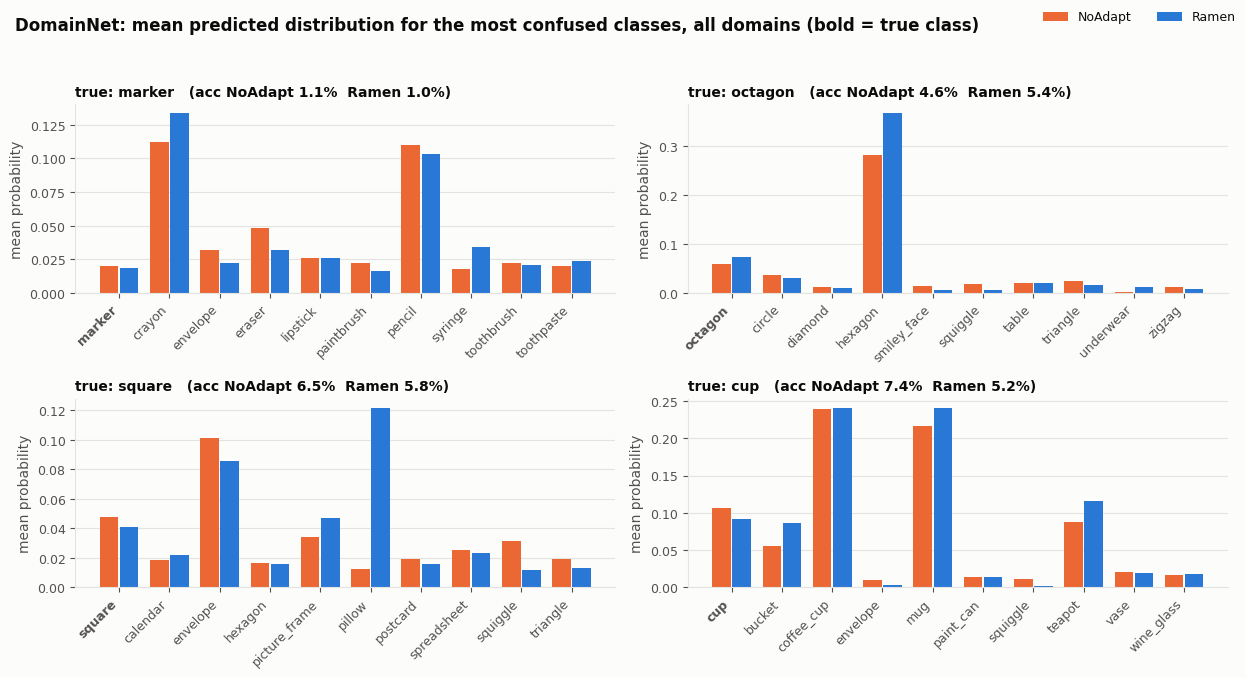

In [6]:
exp.plot_class_probs(n=4);

The highest-error classes can be close to chance, with their mass spread thin. The true classes of the top confused pairs are the ones where a single confuser takes most of the mass:

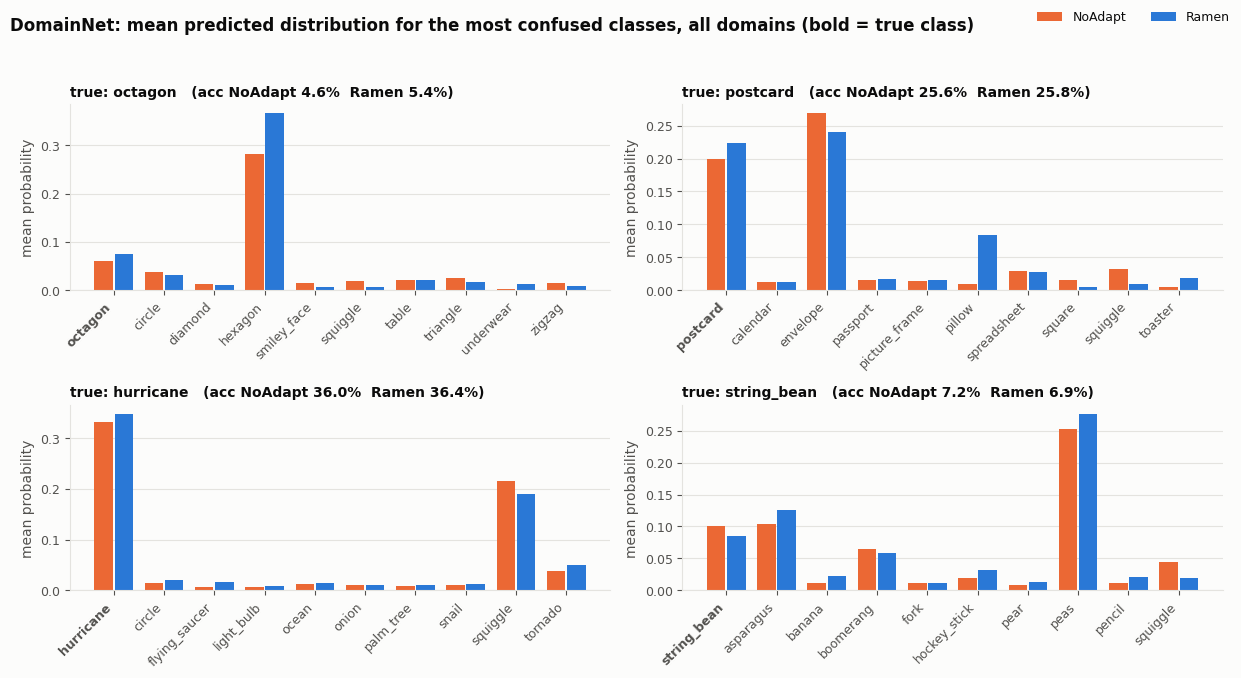

In [7]:
exp.plot_class_probs(classes=list(dict.fromkeys(a for a, _ in pairs.index))[:4]);

worst domain for Ramen: quickdraw


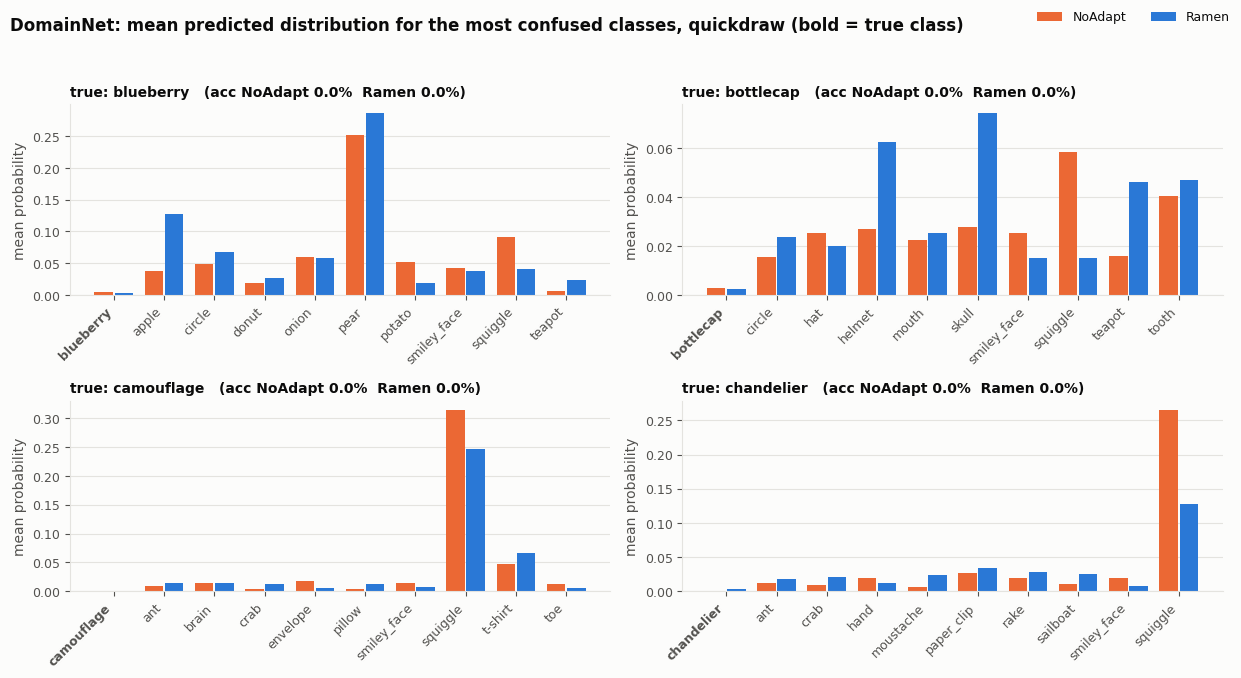

In [8]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst domain for Ramen:', worst)
exp.plot_class_probs(domain=worst, n=4);

## 4. True class vs its confuser, per sample
The mean hides the spread. For each top confused pair (A → B), this is a histogram of `p(A) − p(B)` over the samples of true class A. Mass near 0 means the model is torn between the two. Mass far below 0 means it is confidently wrong.

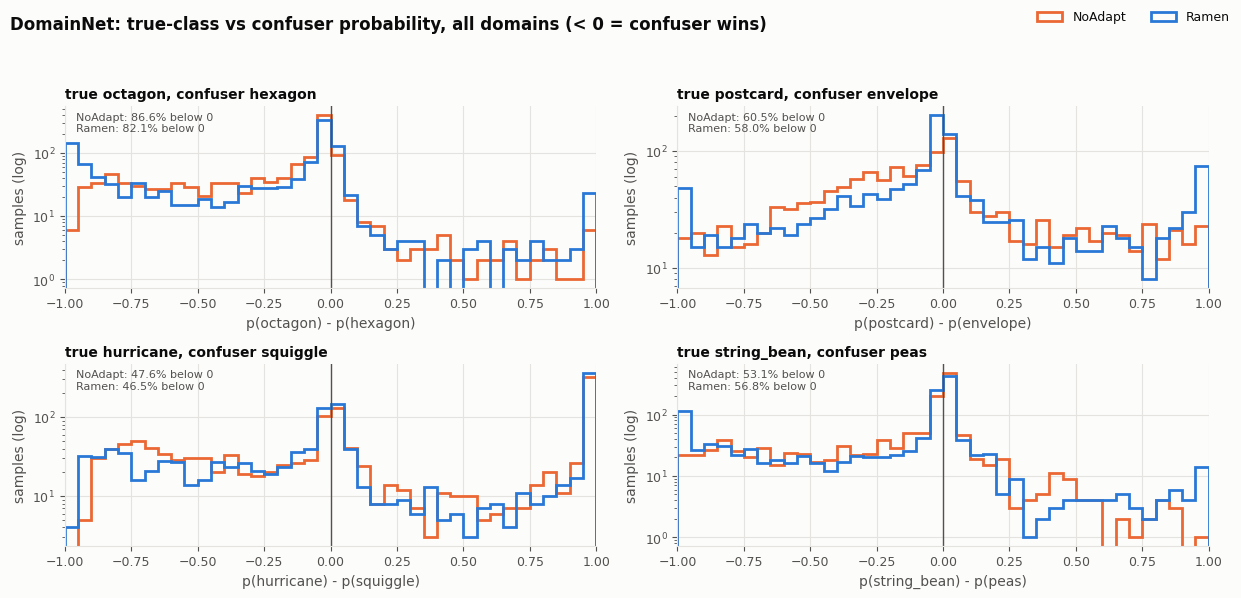

In [9]:
exp.plot_confusion_margin(top_k=4);

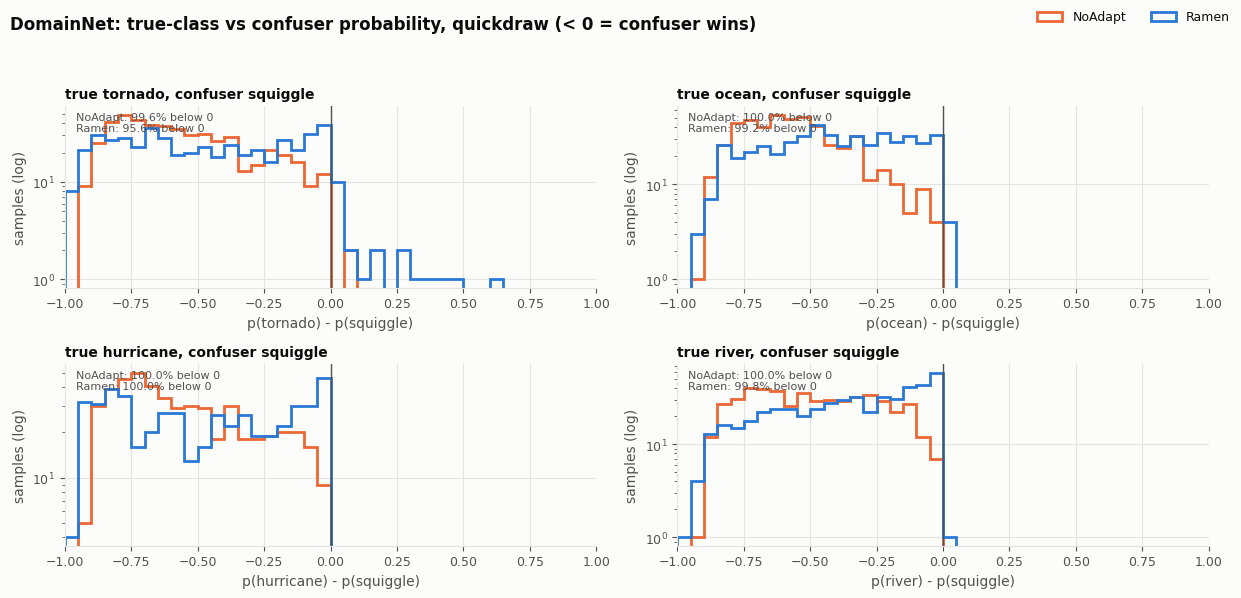

In [10]:
exp.plot_confusion_margin(domain=worst, top_k=4);

## 5. One failed image
A single test image next to both methods' predicted distribution (true class plus the 14 most probable others). By default `pick_failure` takes the top confused pair, keeps samples that NoAdapt got right but Ramen got wrong (`kind='broken'`), and returns the one Ramen is most confident on. Use `pair=(...)`, `kind='wrong'`, `domain=...` or `rank=1, 2, ...` to look at others.

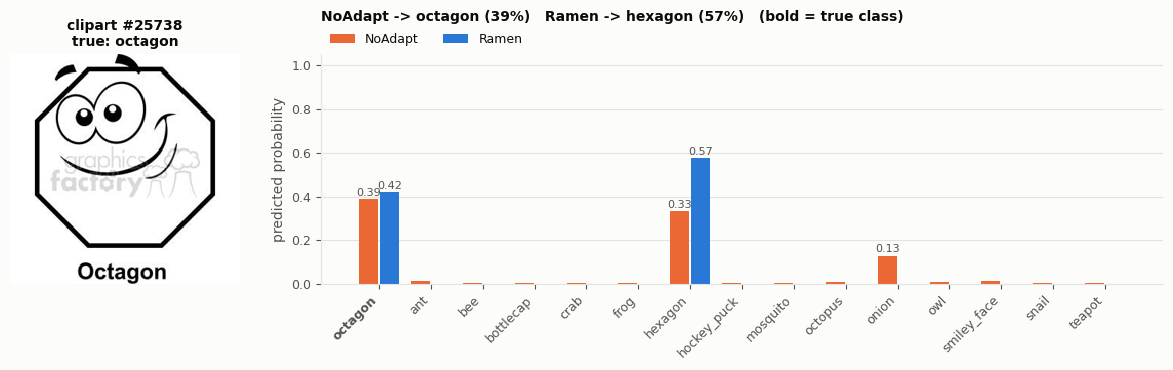

In [11]:
try:
    d_idx, s_idx = exp.pick_failure()
except ValueError as e:  # the top pair may have no 'broken' samples
    print(e, '-> showing any Ramen error on that pair instead')
    d_idx, s_idx = exp.pick_failure(kind='wrong')
exp.plot_sample_probs(d_idx, s_idx);